# Vehicle CO2 Emissions: a leakage-free evaluation

The original notebook reports **R² 0.9972** on a random 60/20/20 split. The dataset has
**exact duplicate rows**, so some test rows are identical to training rows and the score is
partly memorisation. This notebook re-scores the same model three ways:

1. **Reproduction**: duplicates kept, the notebook's random split.
2. **Deduplicated, random split**: exact duplicates removed first.
3. **Deduplicated, grouped 5-fold** by (Make, Model): a vehicle model never appears in both
   training and test, which is the honest question ("how well does it predict a model it has not seen?").

It also compares against two simple baselines under the same grouped folds. The code mirrors
`evaluation/reevaluate.py` in the GitHub repository.

In [1]:
import glob, os
from pathlib import Path

def find_csv() -> Path:
    for pattern in ["/kaggle/input/**/CO2 Emissions_Canada.csv"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return Path(hits[0])
    if os.environ.get("CO2_CSV"):
        return Path(os.environ["CO2_CSV"])
    import kagglehub
    return Path(kagglehub.dataset_download("debajyotipodder/co2-emission-by-vehicles")) / "CO2 Emissions_Canada.csv"

CSV = find_csv()
print(CSV.name)

CO2 Emissions_Canada.csv


In [2]:
import json
import os
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "CO2 Emissions(g/km)"
FUEL_COMB = "Fuel Consumption Comb (L/100 km)"


def features(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """The notebook's feature engineering (cell 7), unchanged."""
    out = df.copy()
    out["engine_per_cylinder"] = out["Engine Size(L)"] / out["Cylinders"]
    out["city_hwy_ratio"] = out["Fuel Consumption City (L/100 km)"] / out["Fuel Consumption Hwy (L/100 km)"]
    out = out.drop(columns=["Engine Size(L)", "Cylinders", "Fuel Consumption City (L/100 km)",
                            "Fuel Consumption Hwy (L/100 km)", "Fuel Consumption Comb (mpg)"])
    return out.drop(columns=[TARGET]), out[TARGET]


def forest(X: pd.DataFrame) -> Pipeline:
    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = X.select_dtypes(exclude="number").columns.tolist()
    pre = ColumnTransformer([("num", StandardScaler(), numeric),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)])
    return Pipeline([("pre", pre), ("model", RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1))])


def scores(y_true, y_pred) -> dict:
    return {"r2": round(float(r2_score(y_true, y_pred)), 4),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
            "mae": round(float(mean_absolute_error(y_true, y_pred)), 2)}


def random_split_test(df: pd.DataFrame) -> dict:
    X, y = features(df)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
    _, X_test, _, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
    model = forest(X_train).fit(X_train, y_train)
    test_rows = set(map(tuple, X_test.assign(_y=y_test).values.tolist()))
    train_rows = set(map(tuple, X_train.assign(_y=y_train).values.tolist()))
    return {**scores(y_test, model.predict(X_test)), "rows": len(df), "test_rows": len(X_test),
            "test_rows_identical_to_a_training_row": len(test_rows & train_rows)}


def grouped_cv(df: pd.DataFrame, make_model) -> dict:
    groups = df["Make"].astype(str) + " | " + df["Model"].astype(str)
    folds = []
    for train_idx, test_idx in GroupKFold(n_splits=5).split(df, groups=groups):
        train, test = df.iloc[train_idx], df.iloc[test_idx]
        model, X_train, y_train, X_test, y_test = make_model(train, test)
        folds.append(scores(y_test, model.fit(X_train, y_train).predict(X_test)))
    summary = {k: {"mean": round(float(np.mean([f[k] for f in folds])), 4 if k == "r2" else 2),
                   "std": round(float(np.std([f[k] for f in folds])), 4 if k == "r2" else 2)} for k in folds[0]}
    return {**summary, "folds": 5, "groups": int(groups.nunique()), "per_fold": folds}


def forest_case(train, test):
    X_train, y_train = features(train)
    X_test, y_test = features(test)
    return forest(X_train), X_train, y_train, X_test, y_test


def fuel_only(train, test):
    return LinearRegression(), train[[FUEL_COMB]], train[TARGET], test[[FUEL_COMB]], test[TARGET]


def fuel_and_type(train, test):
    cols = [FUEL_COMB, "Fuel Type"]
    pre = ColumnTransformer([("num", "passthrough", [FUEL_COMB]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Fuel Type"])])
    return Pipeline([("pre", pre), ("model", LinearRegression())]), train[cols], train[TARGET], test[cols], test[TARGET]


In [3]:
df = pd.read_csv(CSV)
dedup = df.drop_duplicates().reset_index(drop=True)
print(f"rows: {len(df):,}   exact duplicate rows: {int(df.duplicated().sum()):,}   after dedup: {len(dedup):,}")

rows: 7,385   exact duplicate rows: 1,103   after dedup: 6,282


In [4]:
results = {
    "1. reproduction (duplicates kept, random split)": random_split_test(df),
    "2. deduplicated, random split": random_split_test(dedup),
}
for name, r in results.items():
    print(f"{name:50} R2={r['r2']:.4f}  RMSE={r['rmse']:.2f}  test rows identical to a training row: {r['test_rows_identical_to_a_training_row']}")

1. reproduction (duplicates kept, random split)    R2=0.9972  RMSE=3.03  test rows identical to a training row: 246
2. deduplicated, random split                      R2=0.9968  RMSE=3.52  test rows identical to a training row: 0


In [5]:
grouped = {
    "3. RandomForest, grouped by Make+Model": grouped_cv(dedup, forest_case),
    "baseline: line on combined fuel consumption": grouped_cv(dedup, fuel_only),
    "baseline: fuel consumption + fuel type": grouped_cv(dedup, fuel_and_type),
}
table = pd.DataFrame({name: {"R2 mean": r["r2"]["mean"], "R2 std": r["r2"]["std"],
                             "RMSE mean (g/km)": r["rmse"]["mean"], "RMSE std": r["rmse"]["std"],
                             "MAE mean": r["mae"]["mean"]} for name, r in grouped.items()}).T
print(f"{grouped['3. RandomForest, grouped by Make+Model']['groups']:,} Make+Model groups, 5 folds")
table

2,053 Make+Model groups, 5 folds


,R2 mean,R2 std,RMSE mean (g/km),RMSE std,MAE mean
"3. RandomForest, grouped by Make+Model",0.9937,0.0064,4.15,2.03,2.11
baseline: line on combined fuel consumption,0.8383,0.0284,23.68,1.69,14.51
baseline: fuel consumption + fuel type,0.9901,0.0024,5.84,0.54,3.23


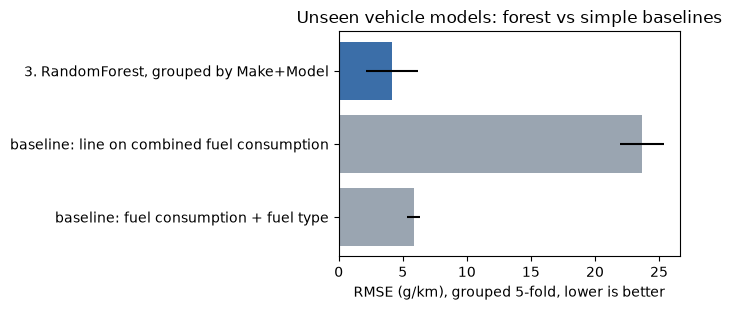

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(grouped)
ax.barh(names, [grouped[n]["rmse"]["mean"] for n in names], xerr=[grouped[n]["rmse"]["std"] for n in names], color=["#3b6ea8", "#9aa5b1", "#9aa5b1"])
ax.invert_yaxis(); ax.set_xlabel("RMSE (g/km), grouped 5-fold, lower is better")
ax.set_title("Unseen vehicle models: forest vs simple baselines")
plt.tight_layout(); plt.show()

In [7]:
import platform, sklearn
print("python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.10 | scikit-learn 1.9.1 | pandas 3.1.1


## What this shows

- **Duplicates:** 1,103 of 7,385 rows are exact duplicates. In the original random split, 246 test rows have an identical copy in training.
- **Leakage was real but small.** Removing duplicates raises RMSE from 3.03 to 3.52 g/km, and R² hardly moves.
- **Unseen vehicle models** (grouped 5-fold; this run's figures are in the table above): R² about 0.994 to 0.995 and RMSE about 4.0 to 4.2 g/km, with MAE about 2.1 g/km. One fold is much harder than the others, hence the RMSE spread.
- **A straight line on fuel consumption and fuel type** already reaches R² 0.990 (RMSE about 5.8 to 5.9). Emissions follow almost directly from the fuel burnt, so a high R² here says little about harder problems. The forest's real gain is about 1.7 to 1.8 g/km RMSE.
- **Version note:** `GroupKFold` assigns groups to folds differently across scikit-learn versions, so the grouped figures move slightly. Observed: 1.6.1 (Kaggle, 2026-11-14) R² 0.9945 ± 0.0052, RMSE 4.06; 1.7.2 R² 0.9948 ± 0.0039, RMSE 4.04; 1.9.1 R² 0.9937 ± 0.0064, RMSE 4.15. Quote the range, not the 0.9972 of the leaky split.